# **C16 - Portafolio y Riesgo**
## **Simulación de Procesos Financieros**

---

**Autor:** Francisco Uriel Ledezma Chávez  
**Carrera:** Ingeniería Financiera  
**Institución:** ITESO — Universidad Jesuita de Guadalajara  
**Semestre:** 5° — Simulación de Procesos Financieros  
**Fecha de realización:** 2 de noviembre de 2026

---

**Ejercicio:** invertir un capital de 100,000 pesos en tres portafolios formados con NVDA, BIMBOA, CEMEX y AZN, uno concentrado en NVDA, uno equiponderado y uno con pesos de 10%, 20%, 30% y 40%, para lo cual se descargan tres años de precios históricos, se estiman el rendimiento y la volatilidad logarítmicos de cada activo y del tipo de cambio, se simulan 10,000 precios a un año con el movimiento browniano geométrico, se calculan el número de acciones y el valor final de cada portafolio en pesos y se comparan sus distribuciones con histogramas individuales y superpuestos.

Hasta C15 la simulación sirvió para valuar contratos y para reducir el error de esa valuación, mientras que aquí cambia de propósito, ya que deja de estimar un solo número, el precio, para describir la distribución completa del valor de una inversión, y con ello la dispersión deja de ser un error que conviene reducir y se convierte en el objeto mismo del análisis, el riesgo del portafolio, medido como la variabilidad de su valor final y la probabilidad de terminar por debajo del capital.

## Índice de contenidos

1. Sección 1 — Datos históricos y cotizaciones de clase
2. Sección 2 — Rendimiento y volatilidad logarítmicos
3. Sección 3 — Simulación del precio a un año
4. Sección 4 — Portafolio A, solo NVDA
5. Sección 5 — Portafolio B, equiponderado
6. Sección 6 — Portafolio C, pesos diversos
7. Sección 7 — Comparación de los tres portafolios
8. Sección 8 — Conclusiones

## Importación de bibliotecas

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(67)

## 1. Datos históricos y cotizaciones de clase

La muestra cubre los tres años que van del 2 de noviembre de 2023 al 2 de noviembre de 2026, con los cierres diarios de NVDA y AZN, que cotizan en dólares en Estados Unidos, de BIMBOA y CEMEX, que cotizan en pesos en la Bolsa Mexicana de Valores, y del tipo de cambio USD/MXN, mientras que la última fila no es un cierre descargado sino las cotizaciones tomadas en clase, que fijan el precio inicial de cada activo.

In [2]:
Capital = 100000
Tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
Prices = yf.download(Tickers, start='2023-11-02', end='2026-11-02', progress=False)['Close'][Tickers]
Forex = yf.download(['USDMXN=X'], start='2023-11-02', end='2026-11-02', progress=False)['Close']

# Cotizaciones tomadas en clase el 2 de noviembre; BIMBOA y CEMEX repiten su cierre del 30 de octubre
Prices.loc[pd.Timestamp('2026-11-02'), :] = [202.06, 66.18, 20.23, 186.58]
Forex.loc[pd.Timestamp('2026-11-02'), :] = 18.5657

print("Acciones:", Prices.index[0].date(), "a", Prices.index[-1].date(), "·", len(Prices), "fechas")
print("Cierres por serie:", Prices.count().to_dict(), "· USDMXN:", len(Forex))
pd.concat([Prices, Forex], axis=1).iloc[[0, 1, -2, -1]]

Acciones: 2023-11-02 a 2026-11-02 · 774 fechas
Cierres por serie: {'NVDA': 752, 'BIMBOA.MX': 750, 'CEMEXCPO.MX': 750, 'AZN': 752} · USDMXN: 778


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
Date,,,,,
2023-11-02,43.376450,NaN,NaN,121.751053,17.76235
2023-11-03,44.870991,74.936394,11.458242,121.333717,17.52700
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210
2026-11-02,202.060000,66.180000,20.230000,186.580000,18.56570


La tabla de precios reúne 774 fechas, aunque NVDA y AZN tienen 752 cierres y BIMBOA y CEMEX sólo 750, ya que cada bolsa tiene sus propios días inhábiles, como el 2 de noviembre de 2023, fecha en la que las dos emisoras mexicanas aparecen vacías, mientras que el tipo de cambio suma 778 observaciones, y en la última fila BIMBOA y CEMEX repiten su cierre del 30 de octubre, señal de que tampoco cotizaron el día de la clase.

## 2. Rendimiento y volatilidad logarítmicos

Cada activo se resume en dos cifras anualizadas calculadas sobre rendimientos logarítmicos, la media diaria multiplicada por 252 y la desviación estándar multiplicada por $\sqrt{252}$, y como en C14 la media logarítmica estima $\mu - \sigma^2/2$, de modo que la deriva que recibe el movimiento browniano geométrico se recupera sumándole la mitad de la varianza, mientras que los rendimientos se calculan serie por serie, ya que eliminar de golpe las fechas en que falta algún activo descartaría, en cada día inhábil de una bolsa, dos rendimientos válidos de los activos que sí cotizaron.

$$\hat{m}_i = 252\;\overline{\ln\left(S_{i,t}/S_{i,t-1}\right)}, \qquad \hat{\sigma}_i = \sqrt{252}\;s_{\ln,i}, \qquad \hat{\mu}_i = \hat{m}_i + \frac{\hat{\sigma}_i^2}{2}$$

In [3]:
Rendimientos_Logaritmicos = {}
for ticker in Tickers:
    precios = Prices[ticker].dropna()   # cada bolsa tiene sus propios días inhábiles, así que cada serie se limpia por separado
    Rendimientos_Logaritmicos[ticker] = np.log(precios / precios.shift(1)).dropna()
Rendimientos_Logaritmicos = pd.DataFrame(Rendimientos_Logaritmicos)

Mean = Rendimientos_Logaritmicos.mean() * 252
Std = Rendimientos_Logaritmicos.std() * np.sqrt(252)
Deriva = Mean + 0.5 * Std ** 2   # deriva aritmética que recibe el GBM, como en C14

Rendimientos_Forex_Logaritmicos = np.log(Forex / Forex.shift(1)).dropna()
Mean_Forex = Rendimientos_Forex_Logaritmicos.mean().iloc[0] * 252
Std_Forex = Rendimientos_Forex_Logaritmicos.std().iloc[0] * np.sqrt(252)
Deriva_Forex = Mean_Forex + 0.5 * Std_Forex ** 2

Parametros = pd.DataFrame({
    "Rendimientos diarios": Rendimientos_Logaritmicos.count(),
    "Rendimiento logarítmico anual": Mean,
    "Volatilidad anual": Std,
    "Deriva del GBM": Deriva,
})
Parametros.loc["USDMXN"] = [len(Rendimientos_Forex_Logaritmicos), Mean_Forex, Std_Forex, Deriva_Forex]
Parametros.astype({"Rendimientos diarios": int}).round(4)

,Rendimientos diarios,Rendimiento logarítmico anual,Volatilidad anual,Deriva del GBM
NVDA,751,0.5163,0.4654,0.6246
BIMBOA.MX,749,-0.0418,0.2961,0.0020
CEMEXCPO.MX,749,0.1913,0.3267,0.2446
AZN,751,0.1432,0.2484,0.1741
USDMXN,777,0.0143,0.1100,0.0204


NVDA domina la muestra, ya que pasó de 43.38 a 202.06 dólares en tres años, lo cual equivale a un rendimiento logarítmico de 0.5163 anual con la volatilidad más alta, de 0.4654, y a una deriva de 0.6246 una vez corregida, mientras que en el otro extremo BIMBOA tuvo un rendimiento logarítmico negativo de -0.0418 y una deriva de apenas 0.0020, de modo que el modelo espera que su precio se mantenga prácticamente donde está, y CEMEX y AZN quedan en medio, con derivas de 0.2446 y 0.1741.

El tipo de cambio es la serie más estable, con una volatilidad de 0.1100, menos de la mitad que la de cualquier acción, y una deriva de 0.0204 que anticipa una depreciación moderada del peso, de modo que su efecto sobre NVDA y AZN será pequeño frente a la variación de las propias acciones, aunque no nulo, ya que cada escenario de esos dos activos se multiplica por su propio tipo de cambio simulado.

## 3. Simulación del precio a un año

La simulación proyecta un año, $T = 1$, con 10,000 escenarios del precio final de cada activo y del tipo de cambio, generados con la misma expresión del movimiento browniano geométrico de las sesiones anteriores, aunque con la deriva estimada en lugar de la tasa libre de riesgo, ya que aquí no se valúa un contrato sino que se describe la distribución del valor que el portafolio puede alcanzar, y los precios de NVDA y AZN se convierten a pesos escenario por escenario, multiplicando cada precio simulado en dólares por el tipo de cambio simulado en ese mismo escenario.

Los mismos 10,000 escenarios alimentan después a los tres portafolios, de modo que sus diferencias provienen sólo de la forma en que reparten el capital y no del azar de simulaciones distintas.

$$S_{T,i} = S_{0,i}\, e^{\left(\hat{\mu}_i - \frac{\hat{\sigma}_i^2}{2}\right)T + \hat{\sigma}_i\sqrt{T}\,Z_i}, \qquad S^{MXN}_{T,i} = S^{USD}_{T,i}\cdot X_T$$

In [4]:
def Final_Price(S0, Mean, Std, T, M):
    Z = np.random.normal(0, 1, M)
    S_T = S0 * np.exp((Mean - 0.5 * Std**2) * T + Std * np.sqrt(T) * Z)
    return S_T

In [5]:
T = 1
M = 10000
S0 = Prices.iloc[-1]
Forex_0 = Forex.iloc[-1, 0]

St_Forex_Dis = Final_Price(Forex_0, Deriva_Forex, Std_Forex, T, M)
St_dis = pd.DataFrame({ticker: Final_Price(S0[ticker], Deriva[ticker], Std[ticker], T, M) for ticker in Tickers})

# NVDA y AZN cotizan en dólares: cada escenario se convierte a pesos con su propio tipo de cambio simulado
Dolares = ['NVDA', 'AZN']
S0_MXN = S0.copy()
S0_MXN[Dolares] = S0[Dolares] * Forex_0
St_dis_MXN = St_dis.copy()
St_dis_MXN[Dolares] = St_dis[Dolares].mul(St_Forex_Dis, axis=0)

Simulacion = pd.DataFrame({
    "Precio hoy": S0,
    "Valor esperado teórico S0·e^(μT)": S0 * np.exp(Deriva * T),
    "Media simulada": St_dis.mean(),
    "Precio hoy en MXN": S0_MXN,
    "Media simulada en MXN": St_dis_MXN.mean(),
})
Simulacion.loc["USDMXN"] = [Forex_0, Forex_0 * np.exp(Deriva_Forex * T), St_Forex_Dis.mean(), np.nan, np.nan]
Simulacion.round(4)

,Precio hoy,Valor esperado teórico S0·e^(μT),Media simulada,Precio hoy en MXN,Media simulada en MXN
NVDA,202.0600,377.3524,375.9112,3751.3853,7122.3024
BIMBOA.MX,66.1800,66.3153,66.5641,66.1800,66.5641
CEMEXCPO.MX,20.2300,25.8362,25.8207,20.2300,25.8207
AZN,186.5800,222.0589,221.7783,3463.9883,4201.3417
USDMXN,18.5657,18.9483,18.9459,NaN,NaN


Las medias simuladas coinciden con el valor esperado teórico $S_0 e^{\mu T}$ en los cinco casos, como en AZN, que parte de 186.58 dólares y tiene un valor esperado de 222.06 frente a una media simulada de 221.78, o en el tipo de cambio, que pasa de 18.5657 a un valor esperado de 18.9483 frente a 18.9459 simulado, lo cual confirma que los 10,000 escenarios reproducen la deriva que se les asignó, mientras que NVDA ilustra el peso de esa deriva, ya que su precio esperado en un año es de 377.35 dólares, 1.87 veces el actual, y en pesos pasa de 3,751.39 a una media de 7,122.30.

## 4. Portafolio A, solo NVDA

Cada portafolio reparte el capital de 100,000 pesos según sus pesos $\omega_i$, y como sólo pueden comprarse acciones enteras, el número de títulos de cada activo es el cociente entre el monto asignado y su precio inicial en pesos redondeado hacia abajo, de modo que una parte del capital queda sin invertir, el cambio, que no forma parte del valor final, el cual se obtiene en cada escenario sumando el producto del número de acciones por el precio simulado de cada activo.

$$V_{0,i} = \omega_i V_0, \qquad N_i = \left\lfloor \frac{\omega_i V_0}{S_{0,i}} \right\rfloor, \qquad V_T = \sum_i N_i\, S_{T,i}, \qquad \sum_i \omega_i = 100\%$$

In [6]:
def Portafolio(W, Capital, S0_MXN, St_dis_MXN):
    """N_i = ω_i V0 / S0_i redondeado hacia abajo a acciones enteras; V_T = Σ N_i S_T,i en cada escenario, sin el cambio."""
    V0_i = W * Capital
    N_i = np.floor(V0_i / S0_MXN)
    Cambio = Capital - np.sum(N_i * S0_MXN)
    Vt_dis = St_dis_MXN.mul(N_i, axis=1).sum(axis=1).values
    return N_i, Cambio, Vt_dis


def Resumen(N_i, Cambio, Vt_dis):
    Vt = np.mean(Vt_dis)
    print("Acciones compradas:", ", ".join(f"{t} {int(n)}" for t, n in N_i.items()))
    print(f"Invertido: {Capital - Cambio:,.2f} · cambio sin invertir: {Cambio:,.2f}")
    print("Valor Inicial del Portafolio:", f"{Capital:,.2f}")
    print("Valor Final del Portafolio:", f"{Vt:,.2f}")
    print("Rendimiento Final del Portafolio:", f"{(Vt - Capital) / Capital * 100:.2f} %")


def Histograma(distribuciones, titulo, bins=50):
    """distribuciones = {etiqueta: (Vt_dis, color)}; al comparar varias, la transparencia deja ver el traslape."""
    plt.figure(figsize=(10, 6))
    if len(distribuciones) > 1:
        # Mismas clases para todas, hasta el percentil 99 de la más dispersa, para comparar las alturas en una sola escala
        valores = [Vt_dis for Vt_dis, _ in distribuciones.values()]
        bins = np.linspace(min(v.min() for v in valores), max(np.percentile(v, 99) for v in valores), 100)
    for etiqueta, (Vt_dis, color) in distribuciones.items():
        plt.hist(Vt_dis, bins=bins, density=True, alpha=0.6 if len(distribuciones) == 1 else 0.45, color=color, label=etiqueta)
    plt.axvline(Capital, color='black', linestyle='--', label='Capital inicial')
    plt.ticklabel_format(axis='x', style='plain')
    plt.title(titulo)
    plt.xlabel('Valor Final (MXN)')
    plt.ylabel('Densidad')
    plt.legend()
    plt.show()

Acciones compradas: NVDA 26, BIMBOA.MX 0, CEMEXCPO.MX 0, AZN 0
Invertido: 97,536.02 · cambio sin invertir: 2,463.98
Valor Inicial del Portafolio: 100,000.00
Valor Final del Portafolio: 185,179.86
Rendimiento Final del Portafolio: 85.18 %


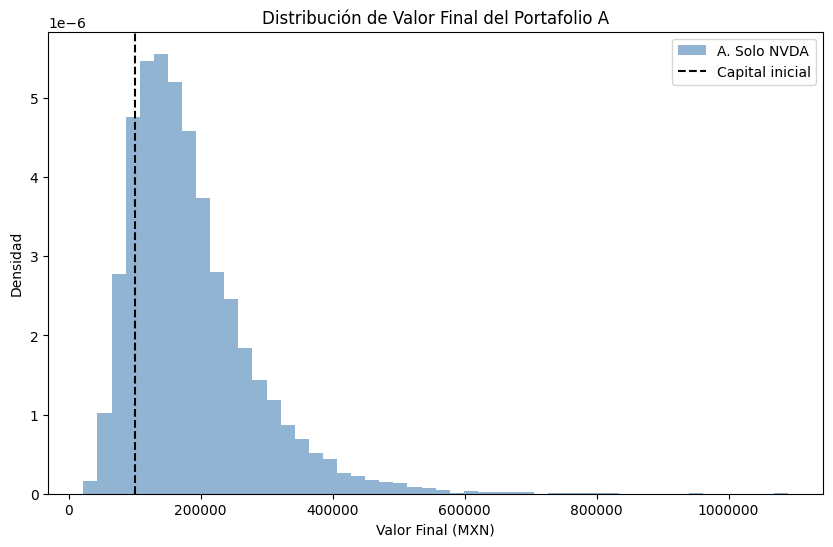

In [7]:
W_A = pd.Series([1, 0, 0, 0], index=Tickers)
N_A, Cambio_A, Vt_A = Portafolio(W_A, Capital, S0_MXN, St_dis_MXN)

Resumen(N_A, Cambio_A, Vt_A)
Histograma({'A. Solo NVDA': (Vt_A, 'SteelBlue')}, 'Distribución de Valor Final del Portafolio A')

El portafolio A invierte todo en NVDA, y como cada acción cuesta 3,751.39 pesos, el capital alcanza para 26 acciones, con 97,536.02 pesos invertidos y 2,463.98 de cambio, mientras que su valor esperado a un año es de unos 185,180 pesos, un rendimiento de 85.18%, cifra que hereda directamente la deriva de 0.6246 de NVDA y que, por lo mismo, depende de que los próximos doce meses repitan el ritmo de los últimos tres.

El histograma muestra la forma característica de un precio lognormal con volatilidad alta, con la mayor parte de la masa a la derecha del capital inicial y una cola derecha que llega cerca del millón de pesos, de modo que unos cuantos escenarios extremos elevan el promedio por encima de lo que obtendría un resultado típico, asimetría que la sección 7 mide al comparar la media con la mediana.

## 5. Portafolio B, equiponderado

Acciones compradas: NVDA 6, BIMBOA.MX 377, CEMEXCPO.MX 1235, AZN 7
Invertido: 96,690.14 · cambio sin invertir: 3,309.86
Valor Inicial del Portafolio: 100,000.00
Valor Final del Portafolio: 129,126.48
Rendimiento Final del Portafolio: 29.13 %


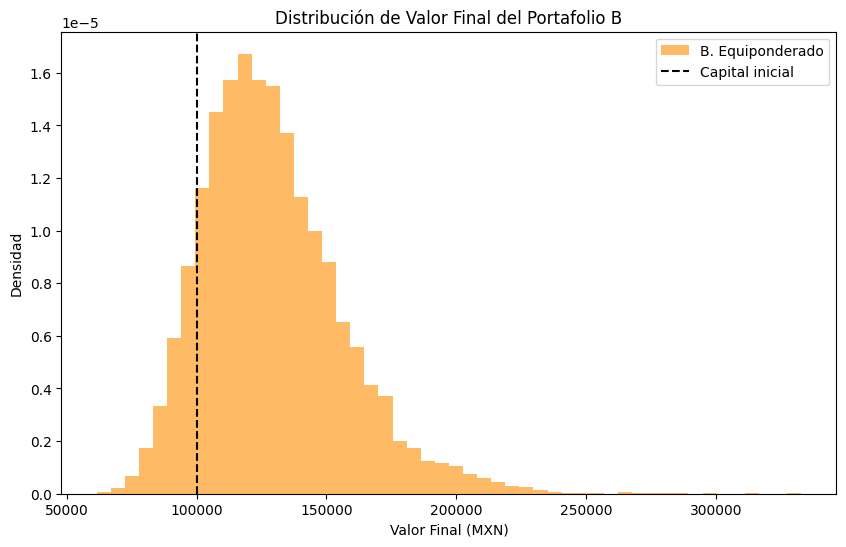

In [8]:
W_B = pd.Series(np.ones(len(Tickers)) / len(Tickers), index=Tickers)
N_B, Cambio_B, Vt_B = Portafolio(W_B, Capital, S0_MXN, St_dis_MXN)

Resumen(N_B, Cambio_B, Vt_B)
Histograma({'B. Equiponderado': (Vt_B, 'DarkOrange')}, 'Distribución de Valor Final del Portafolio B')

El portafolio B asigna 25,000 pesos a cada activo, con lo cual compra 6 acciones de NVDA, 377 de BIMBOA, 1,235 de CEMEX y 7 de AZN, con un cambio de 3,309.86 pesos, y su valor esperado baja a 129,126, un rendimiento de 29.13%, ya que tres cuartas partes del capital pasan a activos cuyas derivas, de 0.0020 a 0.2446, quedan muy por debajo de la de NVDA.

A cambio, el histograma es mucho más compacto y menos asimétrico, con la masa concentrada poco por encima del capital inicial y una cola derecha mucho más corta, porque las variaciones de cuatro activos que se simulan de forma independiente tienden a compensarse entre sí, de modo que un mal año de uno de ellos rara vez coincide con un mal año de todos.

## 6. Portafolio C, pesos diversos

Acciones compradas: NVDA 2, BIMBOA.MX 302, CEMEXCPO.MX 1482, AZN 11
Invertido: 95,573.86 · cambio sin invertir: 4,426.14
Valor Inicial del Portafolio: 100,000.00
Valor Final del Portafolio: 118,828.05
Rendimiento Final del Portafolio: 18.83 %


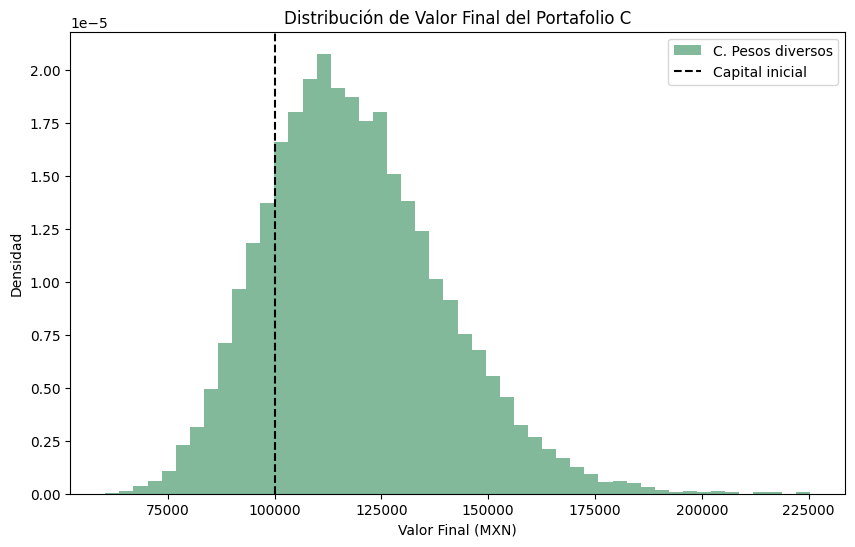

In [9]:
W_C = pd.Series([0.10, 0.20, 0.30, 0.40], index=Tickers)
N_C, Cambio_C, Vt_C = Portafolio(W_C, Capital, S0_MXN, St_dis_MXN)

Resumen(N_C, Cambio_C, Vt_C)
Histograma({'C. Pesos diversos': (Vt_C, 'SeaGreen')}, 'Distribución de Valor Final del Portafolio C')

El portafolio C asigna 10% a NVDA, 20% a BIMBOA, 30% a CEMEX y 40% a AZN, con lo cual compra 2, 302, 1,482 y 11 acciones respectivamente y deja el cambio más alto de los tres, 4,426.14 pesos, ya que las acciones de NVDA y AZN, de 3,751.39 y 3,463.99 pesos, dejan residuos grandes en montos de 10,000 y 40,000 pesos, mientras que su valor esperado es de 118,828, un rendimiento de 18.83%, el menor de los tres, porque reduce NVDA a 10% y lleva el 40% del capital a AZN, cuya deriva de 0.1741 es menos de un tercio de la de NVDA.

El histograma de C es el más estrecho de los tres, aunque su centro queda más cerca del capital inicial, de modo que una parte visible de la distribución cae a la izquierda de la línea punteada, lo cual anticipa que una dispersión menor no implica por sí sola un riesgo de pérdida menor.

## 7. Comparación de los tres portafolios

La comparación reúne primero el número de acciones y el cambio de cada portafolio, después los estadísticos de su valor final, que miden el riesgo con la desviación estándar, los percentiles 5 y 95 y la probabilidad de terminar por debajo del capital, y por último los histogramas superpuestos, en los cuales cada comparación comparte las mismas clases, hasta el percentil 99 de la distribución más dispersa, y la transparencia permite ver dónde se traslapan.

In [10]:
Portafolios = {
    'A. Solo NVDA': (Vt_A, 'SteelBlue'),
    'B. Equiponderado': (Vt_B, 'DarkOrange'),
    'C. Pesos diversos': (Vt_C, 'SeaGreen'),
}

Tabla_N = pd.DataFrame({'A': N_A, 'B': N_B, 'C': N_C}).T.astype(int)
Tabla_N['Cambio'] = [Cambio_A, Cambio_B, Cambio_C]
Tabla_N.round(2)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,Cambio
A,26,0,0,0,2463.98
B,6,377,1235,7,3309.86
C,2,302,1482,11,4426.14


El cambio depende de qué tan bien se divide cada monto asignado entre el precio de su acción, y pasa de 2,463.98 pesos en A a 3,309.86 en B y 4,426.14 en C, y como el valor final no lo incluye, C necesita que sus 95,573.86 pesos invertidos crezcan 4.63% sólo para regresar a los 100,000 iniciales, una desventaja de partida que pesa en los estadísticos siguientes.

In [11]:
Estadisticos = {}
for nombre, (Vt_dis, _) in Portafolios.items():
    Estadisticos[nombre] = {
        "Valor esperado": np.mean(Vt_dis),
        "Rendimiento esperado (%)": (np.mean(Vt_dis) - Capital) / Capital * 100,
        "Desviación estándar": np.std(Vt_dis, ddof=1),
        "Percentil 5": np.percentile(Vt_dis, 5),
        "Mediana": np.median(Vt_dis),
        "Percentil 95": np.percentile(Vt_dis, 95),
        "Probabilidad de terminar bajo el capital (%)": 100 * np.mean(Vt_dis < Capital),
    }

pd.DataFrame(Estadisticos).T.round(2)

,Valor esperado,Rendimiento esperado (%),Desviación estándar,Percentil 5,Mediana,Percentil 95,Probabilidad de terminar bajo el capital (%)
A. Solo NVDA,185179.86,85.18,93340.28,75764.10,165444.62,362671.66,14.39
B. Equiponderado,129126.48,29.13,27093.68,91692.37,125604.71,177122.19,11.58
C. Pesos diversos,118828.05,18.83,20885.61,88112.97,116881.60,155678.66,18.26


La tabla confirma el intercambio entre rendimiento y riesgo, ya que A tiene el valor esperado más alto, 185,180, pero también la desviación estándar más alta, 93,340, y el percentil 5 más bajo, 75,764, lo cual significa que en uno de cada veinte escenarios pierde más de 24% del capital, mientras que B reduce la desviación a 27,094, 71.0% menos, a cambio de bajar el rendimiento esperado de 85.18% a 29.13%.

La asimetría de A se ve en la distancia entre su media y su mediana, ya que el valor esperado supera a la mediana de 165,445 en 19,735 pesos, efecto de la cola derecha que se observó en su histograma, mientras que esa distancia es de 3,522 en B y de 1,946 en C, porque una distribución menos dispersa es también menos asimétrica.

El resultado menos intuitivo es el de C, que tiene la menor desviación estándar, 20,886, y aun así la mayor probabilidad de terminar por debajo del capital, 18.26% frente a 11.58% de B y 14.39% de A, ya que una dispersión baja no protege si el centro de la distribución queda cerca del punto de pérdida, y el de C queda ahí por su deriva menor y por el cambio que no invierte, de modo que B supera a C en valor esperado, mediana, percentil 5 y percentil 95 y sólo pierde frente a él en desviación estándar.

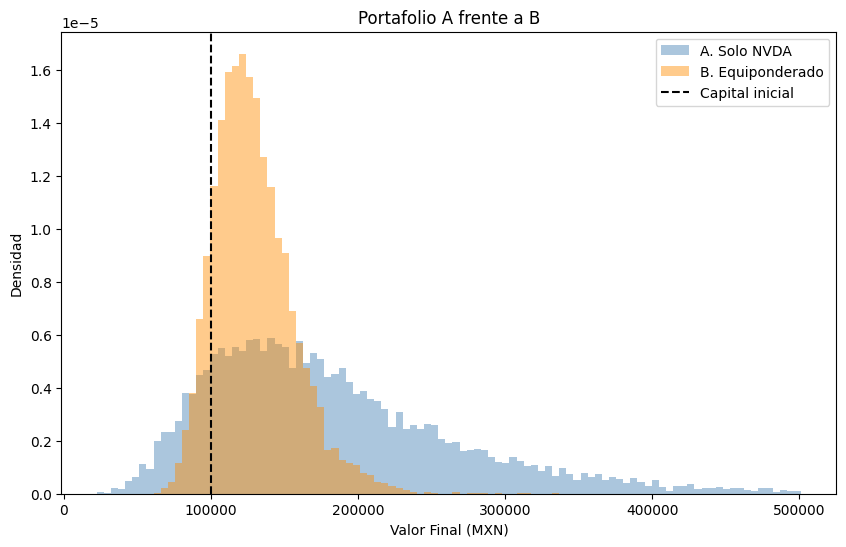

In [12]:
Histograma({k: Portafolios[k] for k in ['A. Solo NVDA', 'B. Equiponderado']}, 'Portafolio A frente a B')

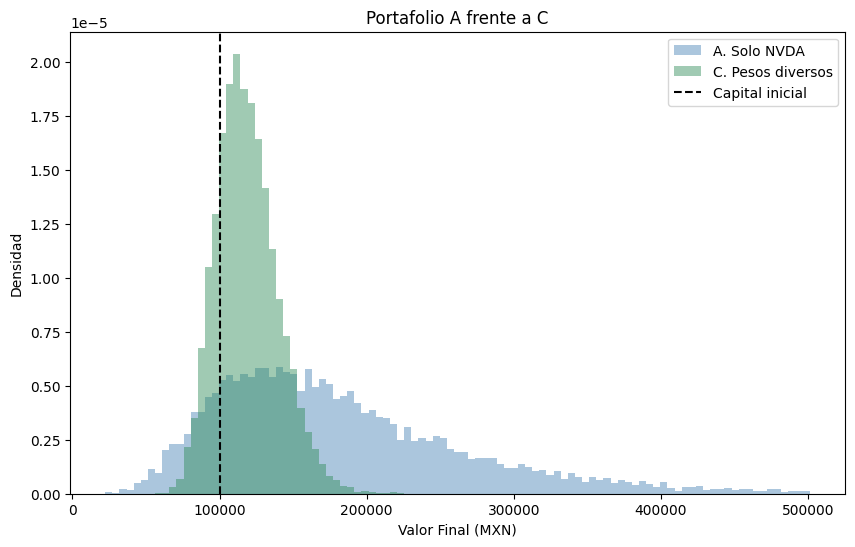

In [13]:
Histograma({k: Portafolios[k] for k in ['A. Solo NVDA', 'C. Pesos diversos']}, 'Portafolio A frente a C')

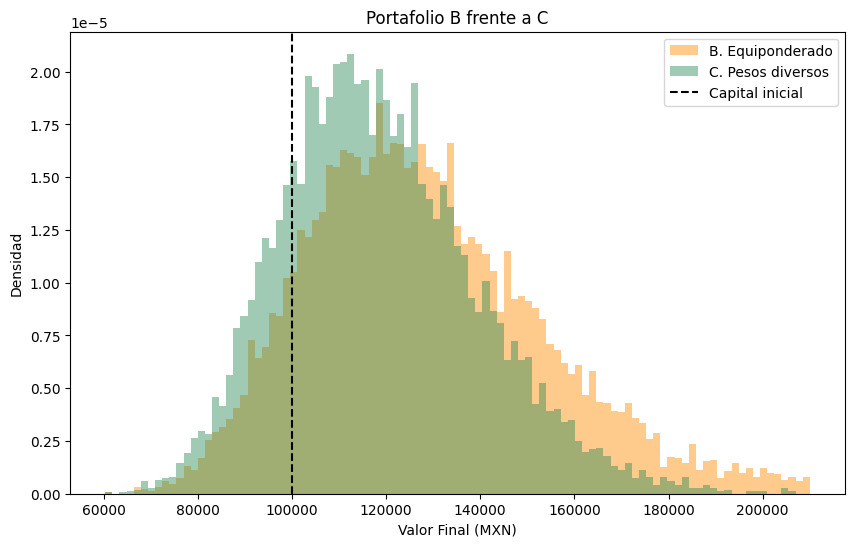

In [14]:
Histograma({k: Portafolios[k] for k in ['B. Equiponderado', 'C. Pesos diversos']}, 'Portafolio B frente a C')

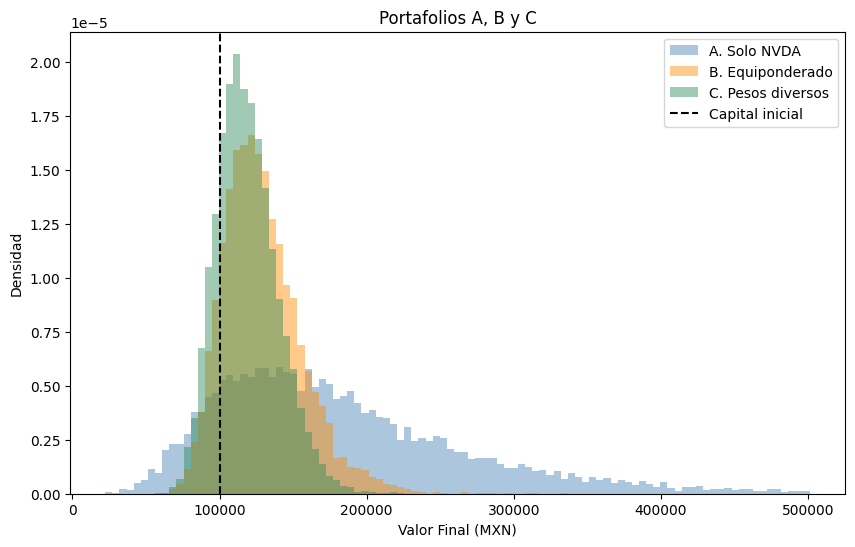

In [15]:
Histograma(Portafolios, 'Portafolios A, B y C')

Los histogramas superpuestos muestran la misma historia en forma visual, ya que frente a A, tanto B como C aparecen como picos altos y estrechos montados sobre la parte izquierda de una distribución mucho más extendida, que es la que concentra las ganancias grandes y también las pérdidas grandes, mientras que B y C se traslapan casi por completo y su diferencia está en el desplazamiento, pues C se ubica a la izquierda de B y deja una fracción mayor de su masa antes de la línea del capital inicial.

La gráfica de los tres portafolios resume la decisión, que no consiste en elegir la distribución menos dispersa sino la que ofrece la mejor combinación entre el valor esperado y la parte de la distribución que cae en pérdida.

## 8. Conclusiones

El ejercicio muestra que la forma de repartir un mismo capital cambia por completo la distribución del valor final, ya que sobre los mismos 10,000 escenarios el portafolio concentrado en NVDA espera terminar en 185,180 pesos con una desviación de 93,340, el equiponderado en 129,126 con 27,094 y el de pesos diversos en 118,828 con 20,886.

La explicación está en la combinación de deriva y diversificación, pues el valor esperado de cada portafolio es la suma de los valores esperados de sus posiciones, de modo que lo domina la posición en NVDA, cuya deriva de 0.6246 es la más alta de la muestra, mientras que la dispersión cae al repartir el capital porque los choques de activos simulados de forma independiente se compensan, y por ello B conserva un rendimiento esperado de 29.13% con una desviación 71.0% menor que la de A.

La consecuencia es que la desviación estándar por sí sola no basta para medir el riesgo de un portafolio, ya que C es el menos disperso y sin embargo el más propenso a terminar en pérdida, con 18.26%, de modo que el riesgo debe leerse junto con el centro de la distribución, y con esa lectura B domina a C en todos los estadísticos salvo la desviación, mientras que A sólo conviene a quien acepte que en uno de cada veinte escenarios pierda más de 24% del capital a cambio de su rendimiento esperado.

Entre los tres, B ofrece el mejor equilibrio, con la menor probabilidad de pérdida, 11.58%, el percentil 5 más alto, 91,692, y un rendimiento esperado de 29.13%, aunque la elección final depende de la tolerancia al riesgo de cada inversionista.

El análisis tiene tres límites que conviene declarar, ya que las derivas se estimaron sobre tres años en los que NVDA multiplicó su precio más de cuatro veces, y C14 mostró que un activo puede cambiar de régimen sin aviso, de modo que el rendimiento de A descansa sobre un supuesto frágil, además de que los activos se simulan de forma independiente, sin la correlación que tienen en la realidad, por lo cual la dispersión de B y C probablemente está subestimada y su ventaja por diversificación exagerada, y por último el cambio que queda sin invertir se deja fuera del valor final, lo cual castiga más a C, cuyo cambio de 4,426.14 pesos equivale a 4.43% del capital, por lo cual la extensión natural es incorporar la correlación entre activos y repetir la comparación con distintos periodos de estimación.